## 2107540 Data Science for Environmental and Sustainability
## Project : Sustainability of Bangkok
### Done by : 6730084521 Chatrphol Ovanonchai

## Overview
This notebook belongs to 

Coursework Project of `2107540 Data Science for Environmental and Sustainability 
Academic Year 2026 Semester 1`

Use for educational purposes only 

> FYI : Mostly of markdowns were written by AI (for saving time) , but codes were written by myself


# 1. Project Title

**Green Space and PM2.5 Across Bangkok's Districts (2021–2024)**

# 2. Environmental Problem

Bangkok often has high PM2.5, especially in the dry season (November–April), and its green space is unevenly distributed: some districts have over 50 m² per person, while inner-city districts have only a few m². Districts with little green space and high PM2.5 face a double disadvantage.

**Goal**

> **Is Bangkok a livable, sustainable city** in terms of air quality and green space — and is this fair across its districts?

**How it is measured** (based on SDG 11: Sustainable Cities and Communities)

| Indicator | Variable | Benchmark |
|---|---|---|
| Air quality (SDG 11.6.2) | Annual mean PM2.5, `percentage_exceed_days` | Thai annual standard 15 µg/m³; WHO 2021 guideline 5 µg/m³; Thai 24-hour standard 37.5 µg/m³ |
| Green space (SDG 11.7.1) | `green_space_per_capita` | Commonly cited minimum of 9 m²/person |

A district that fails **both** benchmarks is a **priority district**.

The dry season is analysed separately because temperature inversion, weak wind, no rain, and biomass burning make PM2.5 much higher than in the wet season.

**Research question**

> Is green space per capita associated with lower PM2.5 levels in Bangkok's districts?

**Sub-questions**

1. Which districts have the most and the least green space per person?
2. Which districts have the highest PM2.5, and how often do they exceed the Thai 24-hour standard?
3. Does the relationship still hold during the dry season?
4. Can districts be grouped into types based on green space, population density, and PM2.5?
5. Do Bangkok and its districts meet the PM2.5 and green space benchmarks?

# 3. Dataset Source

All files are stored in `../Data/` and loaded into a SQLite database in Section 3.1.

| File | Content | Coverage | Source | Used? |
|---|---|---|---|---|
| `bangkok_green_space_by_district.csv` | Green space count and area, district area, population, green space ratio | 50 districts + 1 Bangkok total row | [พื้นที่สีเขียวรายเขต กทม.](https://data.go.th/th/dataset/parkinbangkok) | ✅ |
| `bangkok_pm25_2021.csv` – `bangkok_pm25_2024.csv` | Daily PM2.5 (µg/m³), one column per monitoring station (`02T`, `05T`, …) | 2021, 2022, Jan–Jun 2023, 2024; 96 stations | [ชุดข้อมูล PM2.5 กทม. และปริมณฑล](https://data.go.th/en/dataset/air-quality-bangkok-metropolitan-region1) | ✅ |
| `station_district.csv` *(created)* | Lookup table: station code → district | 96 stations | Air4Thai station list (Pollution Control Department) | ✅ |

In [188]:
## Import libraries
import os
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 3.1 Create the Database

All raw CSV files are loaded **as they are** into a SQLite database (`../Database/bangkok_sustainability.db`) as `raw_*` tables. Cleaning is done in pandas in Section 4, and the cleaned tables (`green`, `pm25`, `pm25_district`) are saved back into the same database.

In [189]:
## Folder paths
DATA_PATH = "../Data"
FIGURE_PATH = "../Figures"
DATABASE_PATH = "../Database"
DB_FILE = f"{DATABASE_PATH}/bangkok_sustainability.db"

os.makedirs(FIGURE_PATH, exist_ok=True)
os.makedirs(DATABASE_PATH, exist_ok=True)

## Constants used throughout the notebook
PM25_STANDARD = 37.5                       # Thai 24-hour PM2.5 standard (µg/m³)
DRY_SEASON_MONTHS = [11, 12, 1, 2, 3, 4]   # November – April

## Connect to the SQLite database
conn = sqlite3.connect(DB_FILE)

## write run_sql command to use sql command
def run_sql(query_cmd , connector) : 
    """Run a SQL query and return the result as a DataFrame."""
    return pd.read_sql_query(sql = query_cmd , con = connector)

def read_and_load_csv_to_db(file_path , connector , table_name , encoding) : 
    # read csv (with encoding)
    df = pd.read_csv(file_path , encoding = encoding)
    # load csv to db
    df.to_sql(name = table_name , con = connector , if_exists = "replace" , index = False) 
    
def execute_sql(command , connector = conn) : 
    connector.execute(command) 
    connector.commit() # to change data 
    
## run_sql wouldn't change data , while execute_sql would change data forever


In [190]:
## Load every raw CSV file into the database
# table name : (file name, encoding)
raw_files = {
    "raw_green":     ("../Data/bangkok_green_space_by_district.csv", "utf-8-sig"),
    "raw_pm25_2021": ("../Data/bangkok_pm25_2021.csv",               "cp874"),      # Thai encoding
    "raw_pm25_2022": ("../Data/bangkok_pm25_2022.csv",               "cp874"),      # Thai encoding
    "raw_pm25_2023": ("../Data/bangkok_pm25_2023.csv",               "utf-8-sig"),
    "raw_pm25_2024": ("../Data/bangkok_pm25_2024.csv",               "utf-8-sig"),
    "station_map":   ("../Data/station_district.csv",                "utf-8-sig"),  # station -> district
}

for each_file in raw_files : 
    read_and_load_csv_to_db(file_path = raw_files[each_file][0] , connector = conn , 
                            table_name = each_file , encoding = raw_files[each_file][1] )
    
# show the tables in the database
run_sql("SELECT name FROM sqlite_master WHERE type='table'" , connector = conn)

,name
0,pm25_district
1,green_space
2,pm25
3,pm_district_green_summary
4,pm25_daily_bkk
5,raw_green
6,raw_pm25_2021
7,raw_pm25_2022
8,raw_pm25_2023
9,raw_pm25_2024


# 4. Data Cleaning and Transformation

Raw tables are read from the database (Section 3.1), cleaned in **pandas**, and the cleaned tables are saved back into the database. SQL is also used as a cross-check: pandas and SQL results must match.

| Dataset | Cleaning / transformation |
|---|---|
| Green space | Remove the Bangkok total row; strip `เขต` from district names; rename columns |
| PM2.5 | Read 2021–2022 with `cp874` encoding; drop empty rows; parse dates (2024 is day/month/year); merge `72T(เก่า)` / `72T(ใหม่)`; remove 1 duplicate date in 2021; reshape wide → long (`melt`); combine 4 years |
| PM2.5 → district | Join with `station_district.csv`; average stations in the same district per day |

The green space per capita is calculated using the following formula:

$$
\text{Green Space per Capita} = \frac{\text{Green Space Area (m}^2\text{)}}{\text{Population}}
$$

The population density is calculated using the following formula:

$$
\text{Population Density} = \frac{\text{Population}}{\text{District Area (m}^2\text{)} / 10^6}
$$

For each district, PM2.5 is summarised as `pm25_mean` (whole period), `pm25_dry` (November–April), and `exceed_days` (% of days above 37.5 µg/m³). The final table has **one row per district**.

## 4.1 Green Space

In [191]:
## get dataframe from database (to do feature engineering)
green_space_df = run_sql("SELECT * from raw_green" , connector = conn) 

## copy dataframe
green_space_df = green_space_df[ green_space_df['id'].notna() ].copy()

## rename columns 
green_space_df_columns = {
    "dis_trict":                                "district",
    "Area size (sq.m.)":                        "green_area_m2",
    "Area size district (sq.m.)":               "district_area_m2",
    "Population":                               "population",
    "Green space ratio (sq.m./person)":         "green_ratio_given",
    "Percentage green space per district area": "green_pct",
}

green_space_df = green_space_df.rename(columns = green_space_df_columns) 

## strip word "เขต" from district names, e.g. "เขตบางรัก" -> "บางรัก"
green_space_df["district"] = green_space_df["district"].str.replace("เขต" , "" , regex = False).str.strip() # use str method

In [192]:
## feature engineering : green_space_per_capita , population_density
green_space_df['green_space_per_capita'] = green_space_df["green_area_m2"] / green_space_df["population"] 

green_space_df["population_density"] = green_space_df["population"] / green_space_df["district_area_m2"] 

In [193]:
## svae dataframe to database
green_space_df.to_sql(name = "green_space", con = conn, if_exists = "replace" , index = False) 

50

In [194]:
## see dataframe
green_space_df.head()

,id,district,amount,Rai,Ngan,Sqaure Wa,green_area_m2,district_area_m2,population,green_ratio_given,green_pct,green_space_per_capita,population_density
0,1.0,คลองเตย,136,256,1,39.96,410159.84,12994000,88304,4.64,3.16,4.644861,0.006796
1,2.0,คลองสาน,49,106,2,9.00,170436.00,6051000,61832,2.76,2.82,2.756437,0.010218
2,3.0,คลองสามวา,283,8236,1,23.10,13178092.40,110686000,215427,61.17,11.91,61.171963,0.001946
3,4.0,คันนายาว,165,4161,1,93.53,6658374.12,25980000,93302,71.36,25.63,71.363681,0.003591
4,5.0,จตุจักร,164,454,1,75.17,727100.69,32908000,154513,4.71,2.21,4.705757,0.004695


## 4.2 PM2.5: combine 4 years and reshape to long format

In [195]:
## list to keep the dataframe of each year
dataframe_pm_4years = []

for each_year in [2021, 2022, 2023, 2024] :
    # Step 1 : get raw table from database
    df = run_sql(f"SELECT * FROM raw_pm25_{each_year}", connector = conn)

    # Step 2 : remove empty rows and the duplicate date
    df = df.dropna(subset = ["Date"])
    df = df.drop_duplicates(subset = "Date")

    # Step 3 : fix station 72T (one station, but named differently each year)
    if each_year == 2021 :      # has 2 columns: old + new -> merge into one
        df["72T"] = df["72T(ใหม่)"].fillna(df["72T(เก่า)"])
        df = df.drop(columns = ["72T(เก่า)", "72T(ใหม่)"])

    if each_year == 2022 :      # has only the new column -> just rename
        df = df.rename(columns = {"72T(ใหม่)": "72T"})

    # Step 4 : change text to date (only 2024 is written as day/month/year)
    df["Date"] = pd.to_datetime(df["Date"], dayfirst = (each_year == 2024))

    # Step 5 : wide -> long (1 row = 1 station on 1 day)
    df = df.melt(id_vars = "Date", var_name = "station", value_name = "pm25") ## wide to long format with melt()

    dataframe_pm_4years.append(df)

In [196]:
## stack 4 years into one dataframe
pm = pd.concat(dataframe_pm_4years, ignore_index = True) 
pm = pm.rename(columns = {"Date": "date"})

## make PM2.5 a number and drop missing values
pm["pm25"] = pd.to_numeric(pm["pm25"], errors = "coerce")
pm = pm.dropna(subset = ["pm25"])

print(len(pm), "rows from", pm["station"].nunique(), "stations")

105720 rows from 96 stations


In [197]:
## save dataframe to database (save date as text YYYY-MM-DD)
pm_to_db = pm.copy()
pm_to_db["date"] = pm_to_db["date"].dt.strftime("%Y-%m-%d")
pm_to_db.to_sql(name = "pm25", con = conn, if_exists = "replace", index = False)

## see dataframe
pm.head()

,date,station,pm25
0,2021-01-01,02T,27.0
1,2021-01-02,02T,32.0
2,2021-01-03,02T,46.0
3,2021-01-04,02T,39.0
4,2021-01-05,02T,50.0


## 4.3 Link PM2.5 to districts and build the final table

The PM2.5 dataset contains Air4Thai stations from **all over Thailand**. Only stations located in Bangkok are kept, using `station_district.csv` (station locations from the Air4Thai station list).

In [198]:
## only merge on declared district (note : pm = pm2.5 dataframe for all 4 years)
station_map = run_sql("SELECT station , district FROM station_map" , connector = conn)
pm_district = pm.merge(station_map , on = "station" , how = "inner")

## find mean doe each day per district 
daily_pm = pm_district.groupby(['district' , 'date'] , as_index = False)['pm25'].agg("mean")

## add new column 
daily_pm["exceed_standard"] = daily_pm["pm25"] > PM25_STANDARD # True/False
daily_pm["dry_season"] = daily_pm["date"].dt.month.isin(DRY_SEASON_MONTHS) # True/False -> Nov to Apr

## groupby 1 row per district 
summary_pm = daily_pm.groupby("district").agg( # get column as result from groupby
    pm25_mean = ("pm25" , "mean") , # mean value of pm throughout 4 years
    percentage_exceed_days = ("exceed_standard" , "mean") , # proportion of exceed_standard days (0 to 1)
    n_days = ("pm25" , "count") # days having pm2.5
)

## multiply 100 to percentage & reset index
summary_pm["percentage_exceed_days"] = summary_pm["percentage_exceed_days"] * 100
summary_pm = summary_pm.reset_index()

In [199]:
summary_pm

,district,pm25_mean,percentage_exceed_days,n_days
0,ดินแดง,32.180818,27.515723,1272
1,ธนบุรี,25.119671,16.065831,1276
2,บางขุนเทียน,30.630837,23.505976,1255
3,บางนา,23.362689,13.603819,1257
4,ปทุมวัน,26.034500,16.354760,1229
5,พญาไท,17.906750,6.828885,1274
6,ยานนาวา,22.193517,10.777958,1234
7,วังทองหลาง,22.644667,10.745098,1275


In [200]:
## add pm2.5 to green space dataframe
pm_district_green_summary = green_space_df.merge(right = summary_pm , on = "district" , how = "left") # left inner join -> join with "district" 

## save to database
pm_district_green_summary.to_sql(name = "pm_district_green_summary" , con = conn , if_exists = "replace" , index = False)

## clean NA out from pm25_mean column 
pm_district_green_summary[ pm_district_green_summary["pm25_mean"].notna() ]  

,id,district,amount,Rai,Ngan,Sqaure Wa,green_area_m2,district_area_m2,population,green_ratio_given,green_pct,green_space_per_capita,population_density,pm25_mean,percentage_exceed_days,n_days
7,8.0,ดินแดง,111,206,0,89.00,329956.00,8354000,109047,3.03,3.95,3.025815,0.013053,32.180818,27.515723,1272.0
12,13.0,ธนบุรี,104,280,0,83.12,448332.48,8551000,95666,4.69,5.24,4.686435,0.011188,25.119671,16.065831,1276.0
18,19.0,บางขุนเทียน,202,30379,0,9.25,48606436.99,120687000,185160,262.51,40.27,262.510461,0.001534,30.630837,23.505976,1255.0
21,22.0,บางนา,111,749,3,97.55,1199990.20,18789000,84574,14.19,6.39,14.188642,0.004501,23.362689,13.603819,1257.0
26,27.0,ปทุมวัน,42,421,2,46.00,674584.00,8369000,38560,17.49,8.06,17.494398,0.004607,26.034500,16.354760,1229.0
29,30.0,พญาไท,142,235,1,72.35,376689.40,9595000,62275,6.05,3.93,6.048806,0.006490,17.906750,6.828885,1274.0
34,35.0,ยานนาวา,133,631,1,23.72,1010094.88,16662000,72413,13.95,6.06,13.949082,0.004346,22.193517,10.777958,1234.0
39,40.0,วังทองหลาง,131,353,2,84.30,565937.19,19265000,102281,5.53,2.94,5.533161,0.005309,22.644667,10.745098,1275.0


## 4.4 Summary of Cleaned Data

After cleaning, the notebook has the following DataFrames. The main table used in Sections 5–8 is **`pm_district_green_summary`**.

| DataFrame | Saved in database as | 1 row = | Size | Main columns |
|---|---|---|---|---|
| `green_space_df` | `green_space` | 1 district | 50 rows × 13 columns | `district`, `green_area_m2`, `district_area_m2`, `population`, `green_pct`, `green_space_per_capita`, `population_density` |
| `pm` | `pm25` | 1 station on 1 day (all of Thailand) | 105,720 rows × 3 columns | `date`, `station`, `pm25` |
| `station_map` | `station_map` | 1 Bangkok station | 10 rows × 2 columns | `station`, `district` |
| `pm_district` | – | 1 Bangkok station on 1 day | 12,479 rows × 4 columns | `date`, `station`, `pm25`, `district` |
| `daily_pm` | – | 1 district on 1 day | 10,072 rows × 5 columns | `district`, `date`, `pm25`, `exceed_standard` (True/False), `dry_season` (True/False) |
| `summary_pm` | – | 1 district (with a station) | 8 rows × 4 columns | `district`, `pm25_mean`, `percentage_exceed_days`, `n_days` |
| **`pm_district_green_summary`** | `pm_district_green_summary` | 1 district | 50 rows × 16 columns | all columns of `green_space_df` + `pm25_mean`, `percentage_exceed_days`, `n_days` |

**How the tables are connected**

```
raw_green ──────────────────────────────► green_space_df ──┐
                                                           ├──► pm_district_green_summary
raw_pm25_2021–2024 ──► pm ──► pm_district ──► daily_pm ──► summary_pm ──┘
                              ▲
                  station_map ┘  (keep only Bangkok stations)
```

**Notes**

- Only **8 of 50 districts** have PM2.5 data (10 Bangkok stations). The other 42 districts have `NaN` in the PM2.5 columns.
- `pm` still contains stations from all over Thailand; `pm_district` and the tables after it contain Bangkok only.
- Dates cover **2021-01-01 to 2024-12-31** (2023 only January–June).

# 5. Exploratory Data Analysis (EDA)

The goal of this section is to **understand the data and check its quality** before the analysis in Section 6. Plots here are quick, exploratory plots; the final, presentation-ready figures are in Section 7.

| Sub-section | What to check | Output |
|---|---|---|
| 5.1 Overview | Shape, data types, missing values of each table; **coverage** — how many districts have a PM2.5 station, and how many stations report each year | Printed tables |
| 5.2 Descriptive statistics | Mean, median, min, max, SD of the district table (`green_space_per_capita`, `green_pct`, `population_density`, `pm25_mean`, `percentage_exceed_days`) and **skewness** | `.describe()` + `.skew()` |
| 5.3 PM2.5 trends over time | Daily Bangkok-wide PM2.5 for each year (2021–2024) with the 37.5 µg/m³ standard; month × year pattern to show seasonality | Subplots (one per year) + month × year heatmap |
| 5.4 Distributions & outliers | Green space per capita (normal vs. log scale — shows why log / Spearman are needed); daily PM2.5 by year and by season; **outlier check** on Bangkok stations (keep or remove, and why) | Histograms + boxplots + summary |

**Points to keep in mind**

- Only **8 of 50 districts** have PM2.5 data, so every PM2.5–green space comparison is based on 8 points.
- **2023 covers January–June only** (mostly dry season), so its yearly mean is biased upward.
- The number of reporting stations changes each year (77 → 96).

#### 5.1) Overview: Shape, Data Types, Missing Values & Coverage
> Check each table, then count how many districts have a PM2.5 station and how many stations report each year.

In [201]:
## Shape , Data Type & Missing Values : pm_district_green_summary
print(pm_district_green_summary.shape)
print("----")
print(pm_district_green_summary.isnull().sum())
print("----")
print(pm_district_green_summary.info())

(50, 16)
----
id                         0
district                   0
amount                     0
Rai                        0
Ngan                       0
Sqaure Wa                  0
green_area_m2              0
district_area_m2           0
population                 0
green_ratio_given          0
green_pct                  0
green_space_per_capita     0
population_density         0
pm25_mean                 42
percentage_exceed_days    42
n_days                    42
dtype: int64
----
<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      50 non-null     float64
 1   district                50 non-null     str    
 2   amount                  50 non-null     int64  
 3   Rai                     50 non-null     int64  
 4   Ngan                    50 non-null     int64  
 5   Sqaure Wa               50 non-null 

In [202]:
## Shape , Data Type & Missing Values : pm_summary
print(summary_pm.shape)
print("----")
print(summary_pm.isnull().sum())
print("----")
print(summary_pm.info())

(8, 4)
----
district                  0
pm25_mean                 0
percentage_exceed_days    0
n_days                    0
dtype: int64
----
<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   district                8 non-null      str    
 1   pm25_mean               8 non-null      float64
 2   percentage_exceed_days  8 non-null      float64
 3   n_days                  8 non-null      int64  
dtypes: float64(2), int64(1), str(1)
memory usage: 560.0 bytes
None


In [203]:
## Shape , Data Type & Missing Values : pm
print(pm.shape)
print("----")
print(pm.isnull().sum())
print("----")
print(pm.info())

(105720, 3)
----
date       0
station    0
pm25       0
dtype: int64
----
<class 'pandas.DataFrame'>
Index: 105720 entries, 0 to 110665
Data columns (total 3 columns):
 #   Column   Non-Null Count   Dtype         
---  ------   --------------   -----         
 0   date     105720 non-null  datetime64[us]
 1   station  105720 non-null  str           
 2   pm25     105720 non-null  float64       
dtypes: datetime64[us](1), float64(1), str(1)
memory usage: 3.5 MB
None


#### 5.2) Descriptive Statistics & Skewness of the `pm_district_green_summary` table
> Mean, median, min, max, SD with `.describe()`, plus `.skew()` to confirm that green space per capita is highly skewed.

In [204]:
pm_district_green_summary.describe()

,id,amount,Rai,Ngan,Sqaure Wa,green_area_m2,district_area_m2,population,green_ratio_given,green_pct,green_space_per_capita,population_density,pm25_mean,percentage_exceed_days,n_days
count,50.00000,50.000000,50.000000,50.000000,50.00000,5.000000e+01,5.000000e+01,50.000000,50.000000,50.000000,50.000000,50.000000,8.000000,8.000000,8.000000
mean,25.50000,143.080000,2152.140000,1.740000,54.37540,3.444338e+06,3.137474e+07,108451.360000,23.485200,7.500000,23.485554,0.005882,25.009181,15.674756,1259.000000
std,14.57738,61.141469,4813.997308,1.084398,31.91228,7.702265e+06,4.021445e+07,49190.417271,41.463673,6.769736,41.463864,0.003310,4.641016,6.896896,18.837652
min,1.00000,12.000000,6.000000,0.000000,0.98000,9.759480e+03,1.416000e+06,18329.000000,0.530000,0.690000,0.532461,0.000796,17.906750,6.828885,1229.000000
25%,13.25000,111.000000,290.250000,1.000000,25.66500,4.647934e+05,1.072900e+07,74280.500000,4.852500,3.122500,4.849723,0.004276,22.531879,10.769743,1249.750000
50%,25.50000,143.000000,524.000000,2.000000,52.19500,8.391429e+05,1.902700e+07,97582.000000,9.645000,5.815000,9.649622,0.005101,24.241180,14.834825,1264.500000
75%,37.75000,182.750000,2252.500000,3.000000,83.45000,3.604868e+06,3.428575e+07,139804.000000,24.097500,9.272500,24.101027,0.006917,27.183584,18.142564,1274.250000
max,50.00000,283.000000,30379.000000,3.000000,98.42000,4.860644e+07,2.362610e+08,215427.000000,262.510000,40.270000,262.510461,0.018591,32.180818,27.515723,1276.000000


In [205]:
pm_district_green_summary.skew(numeric_only = True)
## skewness > 0.5 -> right-skewed , 
        # -0.5 to 0.5 = normal , 
        # otherwise left-skewed

id                        0.000000
amount                   -0.151606
Rai                       4.736297
Ngan                     -0.353056
Sqaure Wa                -0.173159
green_area_m2             4.736270
district_area_m2          3.396055
population                0.492959
green_ratio_given         4.447092
green_pct                 2.824887
green_space_per_capita    4.447065
population_density        1.501718
pm25_mean                 0.284506
percentage_exceed_days    0.698216
n_days                   -0.801150
dtype: float64

#### 5.3) PM2.5 Trends Over Time (2021–2024)
> Note : Use `daily_pm` (daily values), not `pm_district_green_summary` (already averaged over the whole period).
> - Subplots: one per year, Bangkok-wide daily mean PM2.5 with the 37.5 µg/m³ standard line
> - Month × year heatmap of monthly mean PM2.5 to show the dry-season pattern

In [206]:
## use data from (pm_district_green_summary can't be used bcz data was calcalated average in year)

## get data across every district for each day
pm25_daily_bkk = daily_pm.groupby("date" , as_index = False)["pm25"].agg("mean") # get mean pm in bkk each day

## feature engineering : add column "year" and "month" for easier plotting 
pm25_daily_bkk["month"] = pm25_daily_bkk["date"].dt.month
pm25_daily_bkk["year"] = pm25_daily_bkk["date"].dt.year

pm25_daily_bkk

,date,pm25,month,year
0,2021-01-01,23.87500,1,2021
1,2021-01-02,28.68750,1,2021
2,2021-01-03,41.68750,1,2021
3,2021-01-04,40.43750,1,2021
4,2021-01-05,41.43750,1,2021
...,...,...,...,...
1271,2024-12-27,38.57500,12,2024
1272,2024-12-28,24.75625,12,2024
1273,2024-12-29,21.81875,12,2024
1274,2024-12-30,31.63750,12,2024


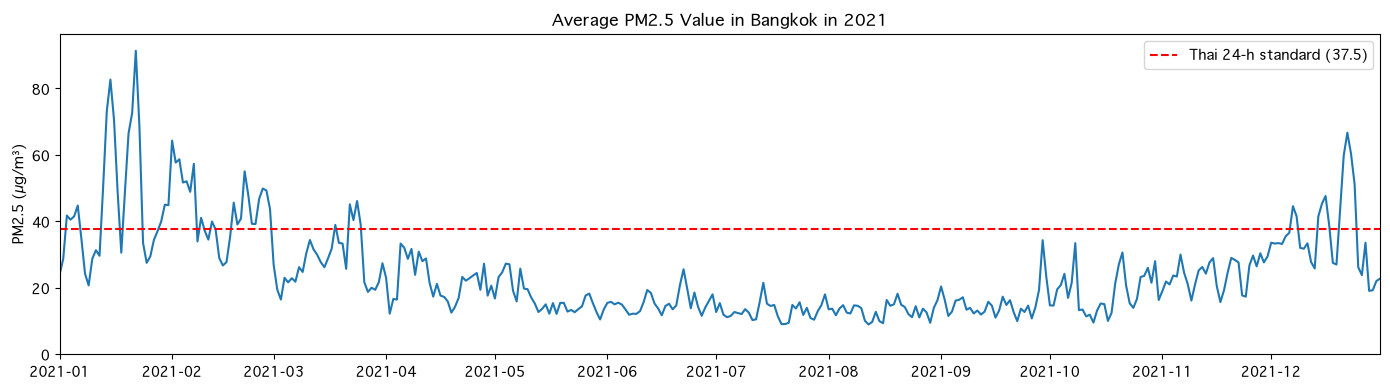

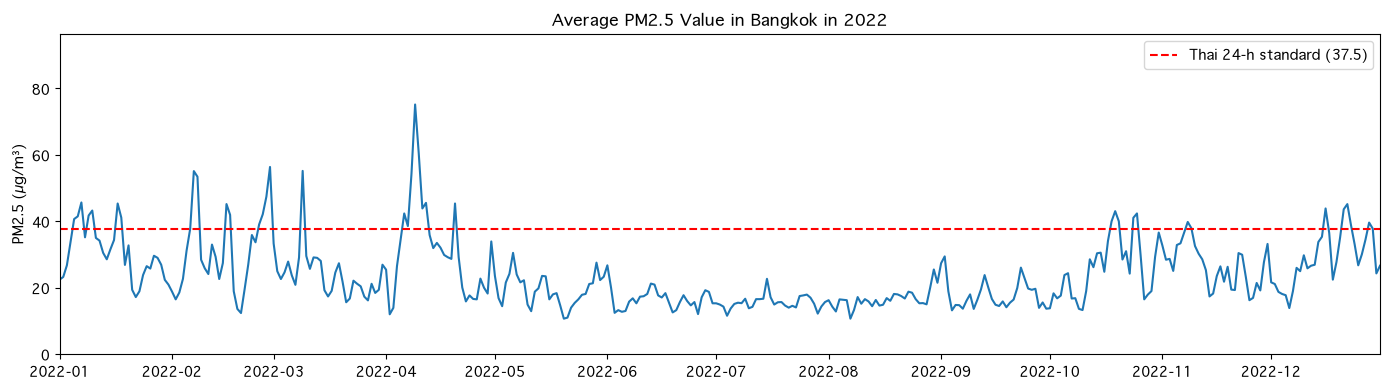

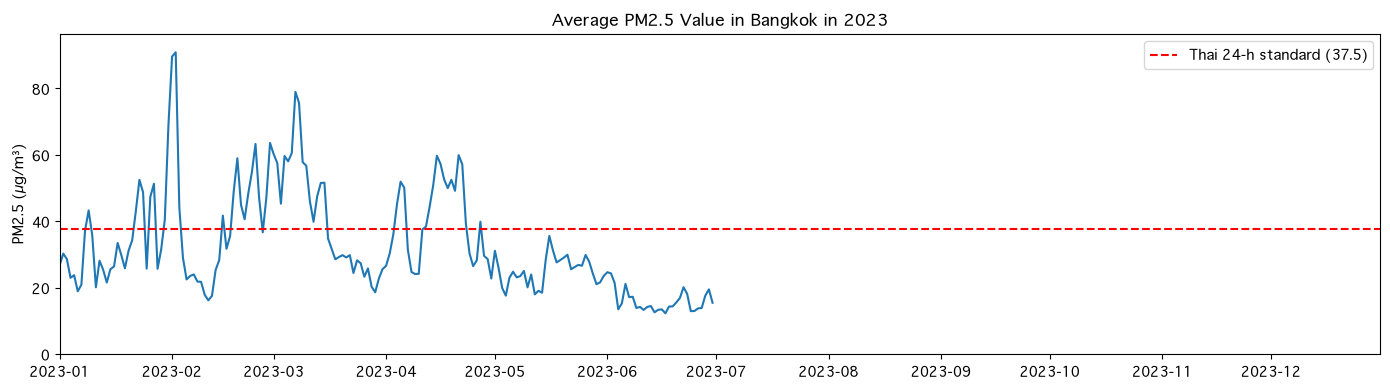

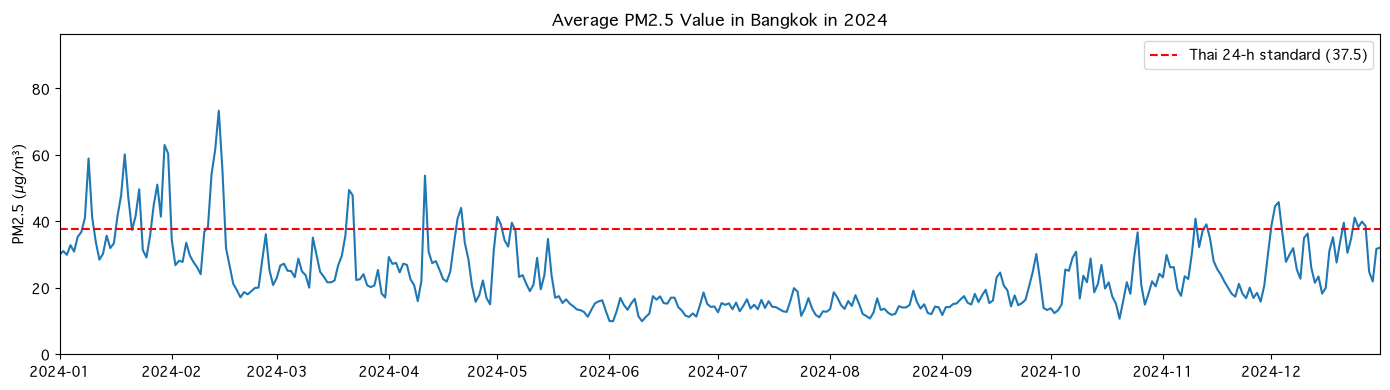

In [207]:
years = [2021, 2022, 2023, 2024]

for each_year in years :
    fig, ax = plt.subplots(figsize = (14, 4))   # new figure for each year

    ## plot data
    data = pm25_daily_bkk[ pm25_daily_bkk["year"] == each_year ]
    ax.plot(data["date"] , data["pm25"])
    
    ## decorate graph 
    ax.axhline(PM25_STANDARD, ls = "--", color = "red", label = "Thai 24-h standard (37.5)")
    ax.set_title(f"Average PM2.5 Value in Bangkok in {each_year}")
    ax.set_ylabel("PM2.5 (µg/m³)")
    ax.set_xlim(pd.Timestamp(f"{each_year}-01-01"), pd.Timestamp(f"{each_year}-12-31"))  # show full year (2023 has only Jan–Jun)
    ax.set_ylim(0, pm25_daily_bkk["pm25"].max() + 5)   # same y-axis for every year (replaces sharey)
    ax.legend()

    plt.tight_layout()
    plt.show()


In [208]:
## upload dataframe to database
pm25_daily_bkk_to_db = pm25_daily_bkk.copy()
pm25_daily_bkk_to_db["date"] = pm25_daily_bkk_to_db["date"].dt.strftime("%Y-%m-%d")
pm25_daily_bkk_to_db.to_sql(name = "pm25_daily_bkk", con = conn, if_exists = "replace", index = False)

1276

#### 5.4) Distributions of Green Space per Capita and Daily PM2.5, and Outlier Check
> - Green space per capita: histogram on a normal scale vs. a log scale (highly skewed → use log scale and Spearman later)
> - Boxplots of daily PM2.5 by year and by season (dry vs. wet)
> - Outlier check: highest PM2.5 values at the Bangkok stations

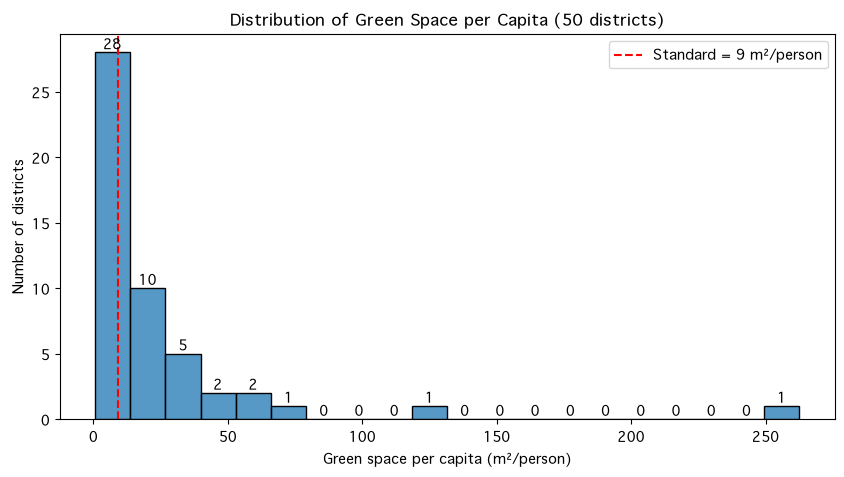

In [209]:
## Green Space per capita
GREEN_SPACE_STANDARD = 9 # standard value for GreenSpacePerCapita 

## data
green_per_capita = pm_district_green_summary["green_space_per_capita"]

## plot histogram
fig, ax = plt.subplots(figsize = (10 , 5))
sns.histplot(data = green_per_capita , bins = 20 , ax = ax)

## benchmark line
ax.axvline(x = GREEN_SPACE_STANDARD , color = "red" , linestyle = "--" ,
           label = f"Standard = {GREEN_SPACE_STANDARD} m²/person")

## show count on top of each bar
ax.bar_label(ax.containers[0])

## decorate
ax.set_title("Distribution of Green Space per Capita (50 districts)")
ax.set_xlabel("Green space per capita (m²/person)")
ax.set_ylabel("Number of districts")
ax.legend()

plt.show()

In [210]:
## Outlier check : Bangkok stations only (pm_district) vs. all stations in Thailand (pm)
print("Bangkok stations  - max PM2.5      :", pm_district["pm25"].max())
print("Bangkok stations  - values > 200   :", (pm_district["pm25"] > 200).sum())
print("Bangkok stations  - values > 100   :", (pm_district["pm25"] > 100).sum())
print("All Thai stations - values > 200   :", (pm["pm25"] > 200).sum())

## Bangkok values above 100 µg/m³ (when and where)
pm_district[pm_district["pm25"] > 100].sort_values("pm25", ascending = False)

Bangkok stations  - max PM2.5      : 137.0
Bangkok stations  - values > 200   : 0
Bangkok stations  - values > 100   : 9
All Thai stations - values > 200   : 94


,date,station,pm25,district
8102,2023-02-01,03T,137.0,บางขุนเทียน
1830,2021-01-22,03T,131.0,บางขุนเทียน
8103,2023-02-02,03T,123.0,บางขุนเทียน
8133,2023-03-08,03T,118.0,บางขุนเทียน
1823,2021-01-15,03T,112.0,บางขุนเทียน
3265,2021-01-16,54T,106.0,ดินแดง
8127,2023-02-28,03T,105.0,บางขุนเทียน
21,2021-01-22,02T,102.0,ธนบุรี
2550,2021-01-22,52T,101.0,ธนบุรี


**Outlier decision: keep all data.**

Values above 200 µg/m³ occur only at stations outside Bangkok (e.g. 73T, 58T, 75T, 57T), which are not used in this analysis (`station_map` keeps only the 10 Bangkok stations). At the Bangkok stations the maximum is **137 µg/m³**, and no value exceeds 200. The few high values (above 100 µg/m³) occur in the dry season and are plausible pollution episodes, not sensor errors, so nothing is removed.

# 6. Data Analysis and Insights Extraction

This section answers the sub-questions from Section 2. Each step produces a table; the figures are in Section 7.

| Step | What we do | Answers |
|---|---|---|
| 6.1 Rank districts | Top / bottom districts by green space per capita; 8 districts ranked by PM2.5 | Sub-questions 1, 2 |
| 6.2 Benchmark check | Compare Bangkok and each district with the PM2.5 and green space benchmarks | Sub-question 5 (the goal) |
| 6.3 Dry vs. wet season | Mean PM2.5 of each district in the dry and wet season | Sub-question 3 |
| 6.4 Correlation | Spearman correlation between green space and PM2.5 (whole period and dry season) | Research question, Sub-question 3 |
| 6.5 Priority districts | Districts that fail **both** benchmarks | The goal (fairness across districts) |

> Green space steps use all 50 districts. PM2.5 steps use only the **8 districts with a station**. Sub-question 4 (grouping districts) is in Section 8.

#### 6.1) Rank Districts
> Which districts have the most / least green space per person, and which have the highest PM2.5?

In [211]:
## Benchmark constants (GREEN_SPACE_STANDARD is defined in Section 5.4)
PM25_ANNUAL_STANDARD = 15     # Thai annual PM2.5 standard (µg/m³)
PM25_WHO_GUIDELINE = 5        # WHO 2021 annual guideline (µg/m³)

## get TOP 5 and BOTTOM 5 of green space per capita
print("Top 5 district having most green space per capita")
display(pm_district_green_summary.sort_values(by = "green_space_per_capita" , ignore_index = True , ascending = False)[["district" , "green_space_per_capita"]].head(5))

print("Top 5 district having least green space per capita")
display(pm_district_green_summary.sort_values(by = "green_space_per_capita" , ignore_index = True , ascending = True)[["district" , "green_space_per_capita"]].head(5))

Top 5 district having most green space per capita


,district,green_space_per_capita
0,บางขุนเทียน,262.510461
1,หนองจอก,130.013043
2,คันนายาว,71.363681
3,คลองสามวา,61.171963
4,มีนบุรี,54.426613


Top 5 district having least green space per capita


,district,green_space_per_capita
0,สัมพันธวงศ์,0.532461
1,ป้อมปราบศัตรูพ่าย,0.968761
2,พระนคร,2.415999
3,บางรัก,2.449012
4,คลองสาน,2.756437


In [212]:
## top 3 district having MOST pm2.5 throughout 4 years
print("Top 3 district having most PM2.5 value throughout 4 years")
display(pm_district_green_summary.sort_values(by = "pm25_mean" , ignore_index = True , ascending = False)[["district" , "pm25_mean"]].head(3))

## top 3 district having LEAST pm2.5 throughout 4 years
print("Top 3 district having least PM2.5 value throughout 4 years")
display(pm_district_green_summary.sort_values(by = "pm25_mean" , ignore_index = True , ascending = True)[["district" , "pm25_mean"]].head(3))

Top 3 district having most PM2.5 value throughout 4 years


,district,pm25_mean
0,ดินแดง,32.180818
1,บางขุนเทียน,30.630837
2,ปทุมวัน,26.034500


Top 3 district having least PM2.5 value throughout 4 years


,district,pm25_mean
0,พญาไท,17.906750
1,ยานนาวา,22.193517
2,วังทองหลาง,22.644667


#### 6.2) Benchmark Check: Is Bangkok Meeting the Standards?
> (a) Bangkok-wide PM2.5 each year vs. the Thai and WHO annual values, (b) Bangkok green space per capita, (c) each district vs. both benchmarks.
> Note: 2023 covers January–June only, so its annual mean is biased upward.

In [213]:
## check pm2.5 average for each year with STANDARD (change Series to DataFrame)
pm25_yearly_bkk = pm25_daily_bkk.groupby(pm25_daily_bkk["date"].dt.year)["pm25"].agg("mean").to_frame("pm25_mean")

## feature engineering : check measurement of Annual and WHO PM2.5 Standard value 
pm25_yearly_bkk["pass_thai_pm25_val"] = pm25_yearly_bkk["pm25_mean"] < PM25_ANNUAL_STANDARD
pm25_yearly_bkk["pass_who_pm25_val"] = pm25_yearly_bkk["pm25_mean"] < PM25_WHO_GUIDELINE 

display(pm25_yearly_bkk)

,pm25_mean,pass_thai_pm25_val,pass_who_pm25_val
date,,,
2021,24.110332,False,False
2022,23.712255,False,False
2023,32.528415,False,False
2024,23.541879,False,False


In [214]:
## check pm2.5 average for each year with STANDARD (change Series to DataFrame)
pm25_monthly_bkk = pm25_daily_bkk.groupby(pm25_daily_bkk["date"].dt.month)["pm25"].agg("mean").to_frame("pm25_mean")

## feature engineering : check measurement of Annual and WHO PM2.5 Standard value 
pm25_monthly_bkk["pass_thai_pm25_val"] = pm25_monthly_bkk["pm25_mean"] < PM25_ANNUAL_STANDARD
pm25_monthly_bkk["pass_who_pm25_val"] = pm25_monthly_bkk["pm25_mean"] < PM25_WHO_GUIDELINE 

display(pm25_monthly_bkk)

,pm25_mean,pass_thai_pm25_val,pass_who_pm25_val
date,,,
1,37.117339,False,False
2,36.620752,False,False
3,29.833871,False,False
4,30.014643,False,False
5,20.723013,False,False
6,15.476733,False,False
7,14.255088,True,False
8,14.531269,True,False
9,16.863770,False,False


#### 6.3) Dry Season vs. Wet Season
> Mean PM2.5 of each district in the dry season (Nov–Apr) and the wet season (May–Oct). This also creates `pm25_dry`, used in 6.4.

In [ ]:
## get pm2.5 on wet & dry season 
pm25_wet_season = daily_pm[ daily_pm["dry_season"] ].groupby("district")["pm25"].agg("mean").rename("pm25_wet")
pm25_dry_season = daily_pm[ ~daily_pm["dry_season"] ].groupby("district")["pm25"].agg("mean").rename("pm25_dry")

display(pm25_dry_season)
display(pm25_wet_season)

district
ดินแดง         24.424013
ธนบุรี         17.064542
บางขุนเทียน    21.473920
บางนา          15.342454
ปทุมวัน        18.868092
พญาไท          11.078689
ยานนาวา        15.139280
วังทองหลาง     15.565523
Name: pm25_dry, dtype: float64

district
ดินแดง         39.283434
ธนบุรี         32.543976
บางขุนเทียน    39.072588
บางนา          30.757492
ปทุมวัน        33.050886
พญาไท          24.179518
ยานนาวา        28.510906
วังทองหลาง     29.179261
Name: pm25_wet, dtype: float64

#### 6.4) Correlation: Is More Green Space Associated with Lower PM2.5?
> Spearman correlation (rank-based, suitable for the skewed green space data) for the whole period and for the dry season only.
> With only 8 districts, |ρ| must be above about 0.74 to be statistically significant, so treat the results as an indication, not proof.

In [216]:
## PM2.5 in the dry season (Nov-Apr) for each district
## district table : 8 districts that have PM2.5 data
district_pm_only_in_bkk = pm_district_green_summary.dropna(subset = ["pm25_mean"]).merge(pm25_dry_season , on = "district")

## Spearman correlation with PM2.5 : whole period vs. dry season
corr_rows = []
for each_factor in ["green_space_per_capita" , "green_pct" , "population_density"] :
    corr_rows.append({
        "factor": each_factor ,
        "corr_with_pm25_all_year": district_pm_only_in_bkk[each_factor].corr(district_pm_only_in_bkk["pm25_mean"] , method = "spearman") ,
        "corr_with_pm25_dry_season":   district_pm_only_in_bkk[each_factor].corr(district_pm_only_in_bkk["pm25_dry"] , method = "spearman") ,
    })

corr_table = pd.DataFrame(corr_rows).round(2)
corr_table

,factor,corr_with_pm25_all_year,corr_with_pm25_dry_season
0,green_space_per_capita,0.02,-0.05
1,green_pct,0.45,0.33
2,population_density,0.12,0.17


In [217]:
pm_on_season = pm_district_green_summary.dropna(subset = ["pm25_mean"])\
                .merge(pm25_dry_season , on = "district").merge(pm25_wet_season , on = "district")

In [218]:
pm_on_season

,id,district,amount,Rai,Ngan,Sqaure Wa,green_area_m2,district_area_m2,population,green_ratio_given,green_pct,green_space_per_capita,population_density,pm25_mean,percentage_exceed_days,n_days,pm25_dry,pm25_wet
0,8.0,ดินแดง,111,206,0,89.00,329956.00,8354000,109047,3.03,3.95,3.025815,0.013053,32.180818,27.515723,1272.0,24.424013,39.283434
1,13.0,ธนบุรี,104,280,0,83.12,448332.48,8551000,95666,4.69,5.24,4.686435,0.011188,25.119671,16.065831,1276.0,17.064542,32.543976
2,19.0,บางขุนเทียน,202,30379,0,9.25,48606436.99,120687000,185160,262.51,40.27,262.510461,0.001534,30.630837,23.505976,1255.0,21.473920,39.072588
3,22.0,บางนา,111,749,3,97.55,1199990.20,18789000,84574,14.19,6.39,14.188642,0.004501,23.362689,13.603819,1257.0,15.342454,30.757492
4,27.0,ปทุมวัน,42,421,2,46.00,674584.00,8369000,38560,17.49,8.06,17.494398,0.004607,26.034500,16.354760,1229.0,18.868092,33.050886
5,30.0,พญาไท,142,235,1,72.35,376689.40,9595000,62275,6.05,3.93,6.048806,0.006490,17.906750,6.828885,1274.0,11.078689,24.179518
6,35.0,ยานนาวา,133,631,1,23.72,1010094.88,16662000,72413,13.95,6.06,13.949082,0.004346,22.193517,10.777958,1234.0,15.139280,28.510906
7,40.0,วังทองหลาง,131,353,2,84.30,565937.19,19265000,102281,5.53,2.94,5.533161,0.005309,22.644667,10.745098,1275.0,15.565523,29.179261


#### 6.5) Priority Districts
> Districts that fail **both** benchmarks: PM2.5 above the Thai annual standard **and** green space below 9 m²/person.

In [219]:
## create benchmark dataframe
bangkok_benchmark_df = district_pm_only_in_bkk.copy() 

## feature engineering : add requirement for "pm2.5" and "green_space_per_capita"
bangkok_benchmark_df["pass_thai_pm25_val"] = bangkok_benchmark_df["pm25_mean"] < PM25_ANNUAL_STANDARD
bangkok_benchmark_df["pass_green_space_cap"] = bangkok_benchmark_df["green_space_per_capita"] > GREEN_SPACE_STANDARD

bangkok_benchmark_df["pass_both_benchmark"] = bangkok_benchmark_df["pass_thai_pm25_val"] & bangkok_benchmark_df["pass_green_space_cap"] 

In [220]:
bangkok_benchmark_df

,id,district,amount,Rai,Ngan,Sqaure Wa,green_area_m2,district_area_m2,population,green_ratio_given,green_pct,green_space_per_capita,population_density,pm25_mean,percentage_exceed_days,n_days,pm25_dry,pass_thai_pm25_val,pass_green_space_cap,pass_both_benchmark
0,8.0,ดินแดง,111,206,0,89.00,329956.00,8354000,109047,3.03,3.95,3.025815,0.013053,32.180818,27.515723,1272.0,24.424013,False,False,False
1,13.0,ธนบุรี,104,280,0,83.12,448332.48,8551000,95666,4.69,5.24,4.686435,0.011188,25.119671,16.065831,1276.0,17.064542,False,False,False
2,19.0,บางขุนเทียน,202,30379,0,9.25,48606436.99,120687000,185160,262.51,40.27,262.510461,0.001534,30.630837,23.505976,1255.0,21.473920,False,True,False
3,22.0,บางนา,111,749,3,97.55,1199990.20,18789000,84574,14.19,6.39,14.188642,0.004501,23.362689,13.603819,1257.0,15.342454,False,True,False
4,27.0,ปทุมวัน,42,421,2,46.00,674584.00,8369000,38560,17.49,8.06,17.494398,0.004607,26.034500,16.354760,1229.0,18.868092,False,True,False
5,30.0,พญาไท,142,235,1,72.35,376689.40,9595000,62275,6.05,3.93,6.048806,0.006490,17.906750,6.828885,1274.0,11.078689,False,False,False
6,35.0,ยานนาวา,133,631,1,23.72,1010094.88,16662000,72413,13.95,6.06,13.949082,0.004346,22.193517,10.777958,1234.0,15.139280,False,True,False
7,40.0,วังทองหลาง,131,353,2,84.30,565937.19,19265000,102281,5.53,2.94,5.533161,0.005309,22.644667,10.745098,1275.0,15.565523,False,False,False


**Key findings** *(fill in after running the analysis)*

- Green space per capita: highest **[district]**, lowest **[district]**; **[n] / 50** districts meet the 9 m²/person benchmark
- PM2.5: highest **[district]**, lowest **[district]**; Bangkok meets the Thai annual standard in **[which years]**
- Dry season PM2.5 is about **[x]** times the wet season
- Green space per capita vs. PM2.5: **[negative / weak / no clear relationship]** (Spearman ρ = **[ ]**); dry season only: **[stronger / weaker / similar]**
- Priority districts (fail both benchmarks): **[list]**

# 7. Data Visualization

Final figures that show the results from Section 6 (exploratory plots are in Section 5). All figures are saved to `../Figures/`.

| Figure | Shows | Answers |
|---|---|---|
| 1. Green space per capita by district | All 50 districts vs. the 9 m²/person benchmark | Sub-questions 1, 5 |
| 2. PM2.5 by district | Mean PM2.5 vs. the Thai annual standard, and % of days above 37.5 µg/m³ (8 districts) | Sub-questions 2, 5 |
| 3. Green space vs. PM2.5 | Scatter plot with both benchmarks; districts on the wrong side of both lines are priority districts | Research question, the goal |
| 4. Correlation heatmap | Spearman correlation between all district variables | Research question |

In [226]:
## Setup for Section 7
# Benchmarks (GREEN_SPACE_STANDARD, PM25_ANNUAL_STANDARD) are defined in Section 5.4 and 6.1

plt.rcParams["font.family"] = ["Thonburi", "Tahoma", "DejaVu Sans"]   # font that can show Thai district names

def save_figure(fig, name):
    """Save a figure into the figures folder."""
    fig.savefig(f"{FIGURE_PATH}/{name}.png", dpi=150, bbox_inches="tight")

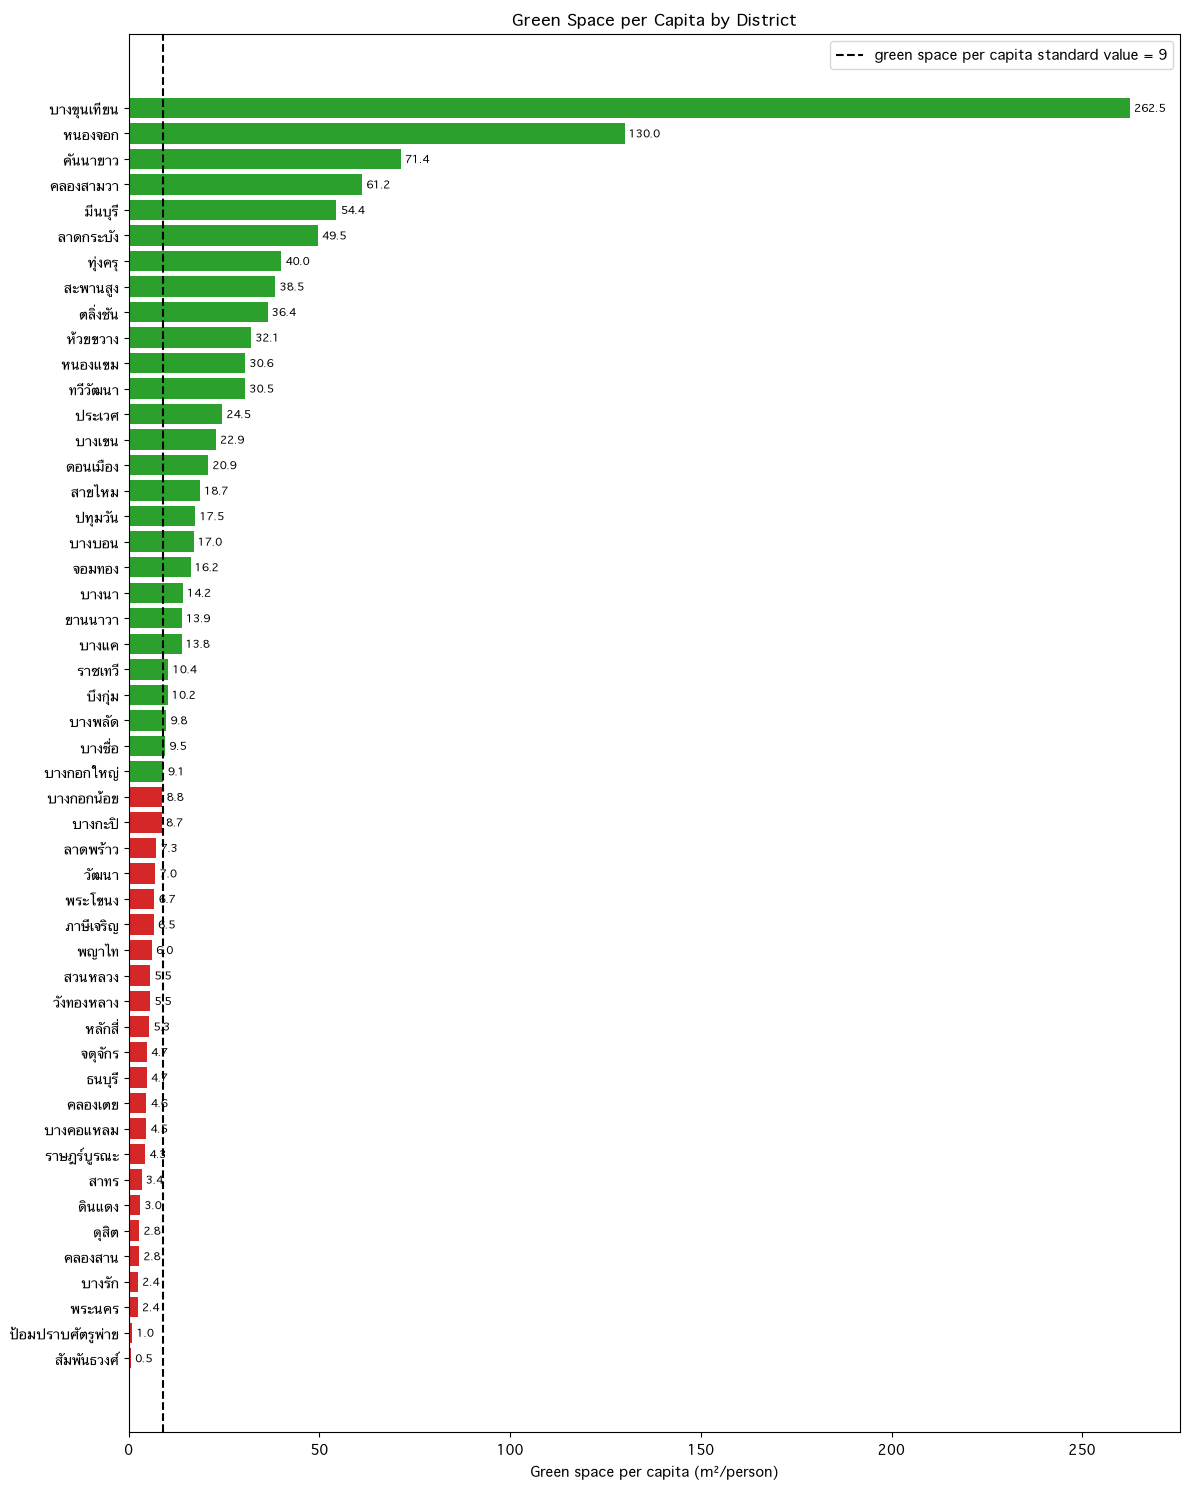

In [242]:
## 1. Green space per capita by district (green = meets benchmark, red = below)
green_space_per_cap_sorted_desc = pm_district_green_summary.sort_values("green_space_per_capita")

## bar color 
bar_colors = np.where(green_space_per_cap_sorted_desc["green_space_per_capita"] >= GREEN_SPACE_STANDARD
                      , "tab:green", "tab:red")

# plot graph
plt.figure(figsize = (12 , 15))

bar_plot = plt.barh(y = green_space_per_cap_sorted_desc["district"] , 
         width = green_space_per_cap_sorted_desc["green_space_per_capita"] , color = bar_colors) 

## standard line & label value
plt.bar_label(bar_plot, fmt="%.1f", padding=3, fontsize=8)
plt.axvline(GREEN_SPACE_STANDARD, color="black", ls="--", label=f"Benchmark = {GREEN_SPACE_STANDARD} m²/person")

## decorate graph
plt.title("Green Space per Capita by District")
plt.xlabel("Green space per capita (m²/person)")
plt.legend(["green space per capita standard value = 9"])
plt.tight_layout()
save_figure(fig, "green_per_capita")
plt.show()


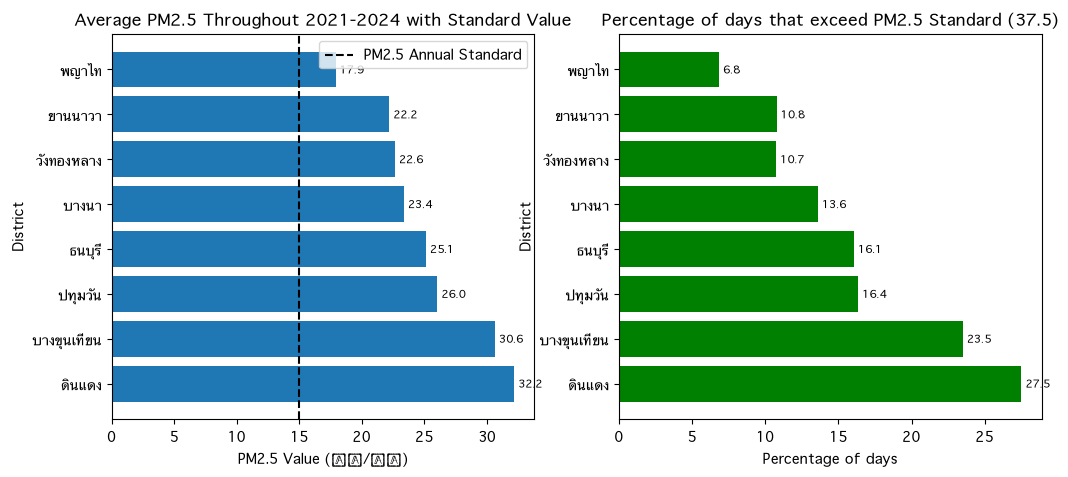

In [272]:
## 2. PM2.5 and % days above the standard by district (8 districts with a station) -> Horizontal Bar
pm25_district_in_bkk = pm_district_green_summary.dropna(subset = "pm25_mean").sort_values(by = "pm25_mean" , ascending = False) 
    ## drop only on pm25_mean column


## plot graph 
fig , (ax1 , ax2) = plt.subplots(nrows = 1 , ncols = 2 , figsize = (12 , 5))

## ax1 (left) : plotting mean PM2.5 vs. Thai annual standard (15)
barh_pm25 = ax1.barh(y = pm25_district_in_bkk["district"] ,
         width = pm25_district_in_bkk["pm25_mean"] ) 

## set vertical line 
ax1.axvline(PM25_ANNUAL_STANDARD , color = "black" , ls = "--") 
ax1.bar_label(barh_pm25, fmt="%.1f", padding=3, fontsize=8)

## decorate graph 1 
ax1.set_title("Average PM2.5 Throughout 2021-2024 with Standard Value") 
ax1.set_xlabel("PM2.5 Value (𝝁𝐠/𝐦𝟑)") 
ax1.set_ylabel("District") 
ax1.legend(["PM2.5 Annual Standard"])

## ax2 (right) : % of days above the Thai 24-hour standard (37.5)
barh_days_pm_above = ax2.barh(y = pm25_district_in_bkk["district"] ,
         width = pm25_district_in_bkk["percentage_exceed_days"] , color = "green" )  

ax2.bar_label(barh_days_pm_above, fmt="%.1f", padding=3, fontsize=8)

## decorate graph 2 
ax2.set_title("Percentage of days that exceed PM2.5 Standard (37.5)") 
ax2.set_xlabel("Percentage of days") 
ax2.set_ylabel("District") 

## ignore warnings
import warnings
warnings.filterwarnings("ignore")

save_figure(fig, "average_pm25_and_percentage_exceed")

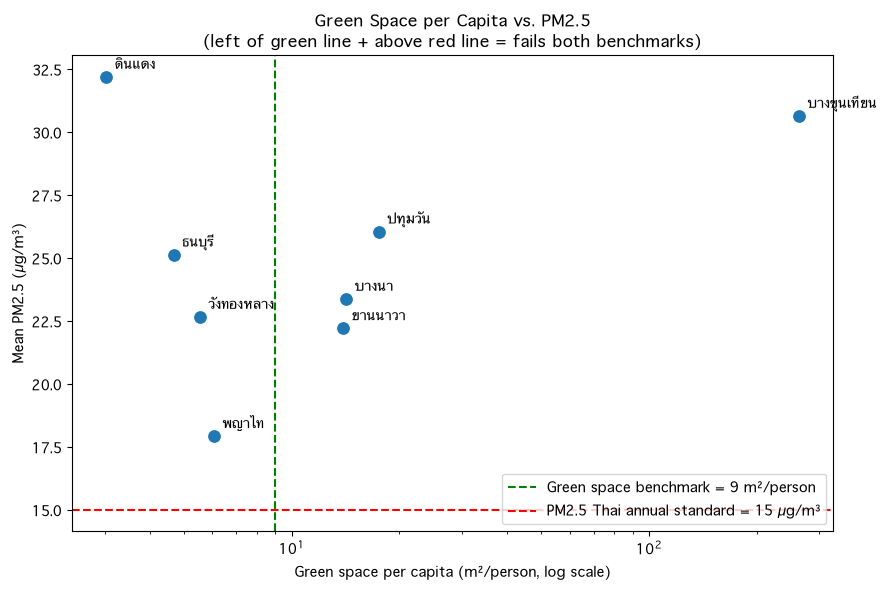

In [ ]:
## 3. Green space per capita vs. PM2.5 with both benchmarks (log x-axis) [AI-Assisted]
scatter_df = pm_district_green_summary.dropna(subset=["pm25_mean"])

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=scatter_df, x="green_space_per_capita", y="pm25_mean", s=100, ax=ax)

## benchmark lines -> split the plot into 4 quadrants
ax.axvline(GREEN_SPACE_STANDARD, color="green", ls="--", label=f"Green space benchmark = {GREEN_SPACE_STANDARD} m²/person")
ax.axhline(PM25_ANNUAL_STANDARD, color="red", ls="--", label=f"PM2.5 Thai annual standard = {PM25_ANNUAL_STANDARD} µg/m³")

## district name next to each point
for _, row in scatter_df.iterrows():
    ax.annotate(row["district"], (row["green_space_per_capita"], row["pm25_mean"]),
                textcoords="offset points", xytext=(6, 6))

ax.set_xscale("log")
ax.set_title("Green Space per Capita vs. PM2.5\n(left of green line + above red line = fails both benchmarks)")
ax.set_xlabel("Green space per capita (m²/person, log scale)")
ax.set_ylabel("Mean PM2.5 (µg/m³)")
ax.legend(loc="lower right")
plt.tight_layout()
save_figure(fig, "green_vs_pm25")
plt.show()

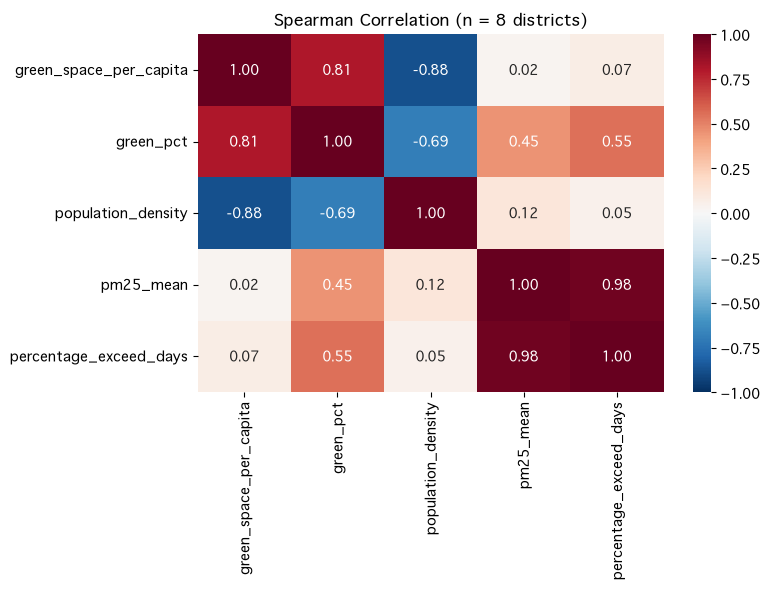

In [224]:
## 4. Correlation heatmap (Spearman, 8 districts with PM2.5 data)
heatmap_cols = ["green_space_per_capita", "green_pct", "population_density", "pm25_mean", "percentage_exceed_days"]
corr_spearman = pm_district_green_summary.dropna(subset=["pm25_mean"])[heatmap_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman Correlation (n = 8 districts)")
plt.tight_layout()
save_figure(fig, "correlation_heatmap")
plt.show()

# 8. Basic Machine Learning (Optional)

With only about 50 districts, the models are kept simple and are used for exploration, not prediction.

1. **K-Means clustering**: group districts by standardised green space per capita, population density, and PM2.5. Choose *k* with the elbow method / silhouette score, then describe each cluster (e.g. "dense, low green, high PM2.5").
2. **Linear regression**: `pm25_mean ~ green_per_capita + pop_density`, evaluated with leave-one-out cross-validation (R², MAE).

In [225]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_predict, LeaveOneOut
from sklearn.metrics import r2_score, mean_absolute_error

## Keep only districts that have PM2.5 data
ml = final.dropna(subset=["pm25_mean"]).copy()
ml["log_green"] = np.log1p(ml["green_per_capita"])       # green space is very skewed

## K-Means clustering (k = 3)
cluster_features = ["log_green", "pop_density", "pm25_mean"]
X_cluster = StandardScaler().fit_transform(ml[cluster_features])
ml["cluster"] = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X_cluster)

print("Mean of each cluster:")
print(ml.groupby("cluster")[["green_per_capita", "pop_density", "pm25_mean"]].mean().round(1))

## Linear regression with leave-one-out cross-validation
X_reg = ml[["log_green", "pop_density"]]
y = ml["pm25_mean"]
y_pred = cross_val_predict(LinearRegression(), X_reg, y, cv=LeaveOneOut())

print(f"\nLOOCV R²: {r2_score(y, y_pred):.3f}   MAE: {mean_absolute_error(y, y_pred):.2f}")

NameError: name 'final' is not defined

# 9. Environmental Interpretation

**[Answer the research question: is more green space per person associated with lower PM2.5? How strong is the relationship, and does it change in the dry season?]**

**[Explain why: e.g. PM2.5 in Bangkok is driven mostly by city-wide and regional sources (traffic, biomass burning, weather), so local green space may have a limited effect on district-level PM2.5.]**

**[Policy implications: which districts should be prioritised for new green space, based on the priority list and clusters?]**

## Limitations

- Temperature data were not available, so the urban heat effect of green space is not analysed.
- Meteorological data (wind speed, rainfall, mixing height / temperature inversion) were not available, so these seasonal drivers of PM2.5 cannot be controlled for; the dry/wet season split is used as a simple proxy.
- PM2.5 is measured at monitoring stations, not over the whole district; some districts have no station or only one.
- The number of stations changes between years, and 2023 covers only January–June (mostly dry season), so its yearly mean is biased upward.
- Green space and population are a single snapshot, while PM2.5 covers 2021–2024.
- Green space area does not reflect the quality or accessibility of green spaces.
- Traffic, industry, and biomass burning outside Bangkok (including transboundary haze) also strongly affect PM2.5, but no data on these sources were used.
- With about 50 districts, correlations and models are sensitive to a few extreme districts.
- Correlation does not imply causation.

## Conclusion

**[2–3 sentences summarising the main finding and its meaning for Bangkok's urban sustainability.]**